# Data & Apprentissage, M2CHPS

## Assignments - Part 2

**Students:** [Surname 1] & [Surname 2]

**Instructor:** [Argyris Kalogeratos](http://kalogeratos.com) (contact: argyris.kalogeratos@ens-paris-saclay.fr).  
**Syllabus:** [http://nvayatis.perso.math.cnrs.fr/CHPScourse.html](http://nvayatis.perso.math.cnrs.fr/CHPScourse.html)

The latest version of this notebook is available on the [instructor's webpage](http://kalogeratos.com/MyCourses/DML-M2HPC/Assignments2.ipynb).

## 0. Before you start

* Work on the assignment either alone or in a team of two (pair). For those that will pick working in a team, the point is not to split the work, but to collaborate! 
* Prepare **a single Jupyter notebook** in a report-like format for all the exercises. Use this notebook as a starting point and place your answers just below each exercise. Describe properly what you do in each step of your solution, followed by your well-commented code implementation that can automatically produce figures and numerical results. Results should also be well-commented and discussed. Your comments can be either in English or in French.
* Mathematical expressions need to be written in tex directly in the notebook (not handwritten!). 
* Important: send your notebook that includes all your work and any additional files you used (e.g. datasets) by email, with a title ``M2CHPS <year> - <Surname1> & <Surname2>``. The title of the notebook should have the surnames of the students. The body of the email should also mention the students' names and how they split the work; if you face difficulties in clarifying this with your classmate, please write separate emails with your views. 
* Always use references for things you reuse (e.g. websites, forums, books, published papers, etc.)
* Do not copy-paste from the internet recipes that do the asked thing (or what is most usually observed: to use something relevant but not exactly what is asked). You need to understand what you use (sources should be properly referenced), adapt it to what each exercise asks for, and comment clearly the results. Poorly commented and explained pieces of work/code will not be taken seriously into account. 
* Copying from one another is not acceptable. We are strict with that: cheating in even one exercise will incur **a zero to all projects** (not just one assignment). Your work will be cross-checked against all the other submissions.
* **Use of LLMs** should be clearly disclosed (where and how they were used): add at the end of your notebook a short cell titled *"Use of LLMs"* that states which tool(s) you used, for which parts, and what you changed in their output. A missing or misleading disclosure is treated as in the previous point. Using such tools to understand a method, debug a problem in the code, or ask for a chunk of python API for trivial operations (e.g. plotting, loading data, etc) is normal. Results that are uncommented or poorly commented will earn little or no credit. However, the grade is on your own experimental work and your understanding of it: an answer that you cannot explain, or that is not supported by your own runs, numbers and figures, counts for nothing.
* The assignments will be examined orally at the end of the semester. Each group of students should be able to explain in about 10 mins all what they did, and answer short questions.
* **Deadline: 23:59 Friday 20/11.**
* **Late submissions:** the maximum possible grade is penalized by 5%/day. E.g. when delivering on time the best grade is 20/20, late submission by one day gets at best 19/20, for two days of delay 18/20...
* **Slot for questions: Monday 26/10 at 14h**. Zoom link: https://kalogeratos.com/zoom. Meeting ID: 243 940 6970 -- Passcode: 15881598

## Exercise 1 - [15%]

A security system relies on a battery ($b$), two sensors ($c$ and $d$), and an alarm ($a$). The random variables $a$, $b$, $c$, $d$ are binary, and $a=1$ when the alarm fires, $b=1$ when the battery functions properly, and $c=1$ and $d=1$ when the respective sensor functions properly. Otherwise, each variable takes the value $0$.

The architecture of the system is as follows: the battery provides power with independent cables to the two sensors, and the sensors feed information to the alarm that can then fire to signify a threat. Each sensor can operate even with only its internal power source that it is equipped with, but in that case it becomes much more sensitive to fail compared to when the external battery is functioning normally. 

The manual of the system says that the probability for the battery to fail is 0.1, and that each sensor fails with probability 0.01 when the battery is ok, and with 0.7 when the battery is not ok. 

Additionally, the manual also informs us that if at least one sensor works fine, then the alarm fires with probability 0.02. Otherwise the alarm fires with 30 times higher probability.

**a)** Draw the graphical model of the system involving the random variables.

**b)** Compute the joint probabilities $p(a,b,c,d)$ and $p(a,c)$. Also check if $c$ and $d$ are independent.

**c)** Suppose **the alarm is silent** and that we check that **only the sensor $d$ works properly**. What is the posterior of having a malfunctioning battery?

**d)** Compute the probability for the alarm to be silent, $p(a=0)$.

**e)** We know that when at least one sensor works fine then the alarm fires with 0.02 (unchanged from the original design), otherwise with 0.6. We want to know how many sensors the system should have (connected like $c$ and $d$ in the initial design) such that the total probability $p(a=1) < 0.05$.

**f)** Suppose **we don't hear any alarm** (with good ears!) and **we have no information about the sensors** functioning. What is the probability for the battery to be malfunctioning?

**g)** Implement a function that generates observations from the probabilistic model at the top. Then make simulations to confirm empirically the estimations you calculated by hand.

## Exercise 1 — Answers (a–f)

### a) Graphical model

The battery affects both sensors, and both sensors affect the alarm:

    b -> c -> a
    b -> d -> a

Given the battery state, the sensors are independent. The joint distribution factors as

$$p(a,b,c,d)=p(b)p(c\mid b)p(d\mid b)p(a\mid c,d).$$

### b) Joint distribution, $p(a,c)$, and independence

The table gives all 16 values of $p(a,b,c,d)$.

| $b$ | $c$ | $d$ | $p(a=1,b,c,d)$ | $p(a=0,b,c,d)$ |
|---:|---:|---:|---:|---:|
|1|1|1|0.0176418|0.8644482|
|1|1|0|0.0001782|0.0087318|
|1|0|1|0.0001782|0.0087318|
|1|0|0|0.0000540|0.0000360|
|0|1|1|0.0001800|0.0088200|
|0|1|0|0.0004200|0.0205800|
|0|0|1|0.0004200|0.0205800|
|0|0|0|0.0294000|0.0196000|

| $p(a,c)$ | $c=0$ | $c=1$ |
|---|---:|---:|
|$a=0$|0.0489478|0.90258|
|$a=1$|0.0300522|0.01842|

The sensor marginals are both 0.921, but $p(c=1,d=1)=0.89109$, not $0.921^2=0.848241$. So $c$ and $d$ are dependent overall, though independent given $b$.

### c) Battery failure given $a=0,c=0,d=1$

Since $d$ works, the alarm stays silent with probability 0.98 under either battery state. Bayes' rule gives

$$p(b=0\mid a=0,c=0,d=1)=\frac{0.1(0.7)(0.3)(0.98)}{0.1(0.7)(0.3)(0.98)+0.9(0.01)(0.99)(0.98)}\approx0.7021.$$

So the battery-failure probability is about 70.2%.

### d) Probability of a silent alarm

Both sensors fail with probability 0.04909, so

$$p(a=1)=0.02(1-0.04909)+0.6(0.04909)=0.0484722,$$
$$\boxed{p(a=0)=0.9515278.}$$

### e) Number of sensors

For $n$ conditionally independent sensors,

$$p(\text{all fail})=0.9(0.01)^n+0.1(0.7)^n,$$
$$p(a=1)=0.02+0.58[0.9(0.01)^n+0.1(0.7)^n].$$

With one sensor $p(a=1)=0.06582$; with two it is 0.0484722. The minimum is **two sensors**.

### f) Battery failure given only a silent alarm

$$p(a=0\mid b=1)=0.979942,\qquad p(a=0\mid b=0)=0.6958.$$

Thus

$$p(b=0\mid a=0)=\frac{0.1(0.6958)}{0.1(0.6958)+0.9(0.979942)}\approx0.073125.$$

After a silent alarm, the chance the battery has failed is about 7.32%.

### g) Simulation

The function samples the battery, then the sensors given the battery, then the alarm given the sensors. With a fixed seed, the estimates can be reproduced. The simulation checks $p(a,b,c,d)$, $p(a,c)$, sensor dependence, the two posteriors, and the alarm rates for one and two sensors. Small differences from the exact values are expected with a finite sample.

### Simulation function


In [1]:
import numpy as np


def sample_security_system(n, rng=None):
    """Generate n independent observations (a, b, c, d) from the model."""
    if rng is None:
        rng = np.random.default_rng()

    # Battery: b=1 means functioning.
    b = (rng.random(n) >= 0.1).astype(int)

    # Each sensor works with probability 0.99 when b=1, and 0.30 when b=0.
    p_sensor_works = np.where(b == 1, 0.99, 0.30)
    c = (rng.random(n) < p_sensor_works).astype(int)
    d = (rng.random(n) < p_sensor_works).astype(int)

    # Alarm fires with probability 0.02 if at least one sensor works;
    # if both fail its firing probability is 30 * 0.02 = 0.60.
    p_alarm = np.where((c == 1) | (d == 1), 0.02, 0.60)
    a = (rng.random(n) < p_alarm).astype(int)

    return {"a": a, "b": b, "c": c, "d": d}


### Run the simulation and compare with the calculations


In [2]:
# A large sample gives stable estimates; the seed makes this run reproducible.
n_sim = 1_000_000
obs = sample_security_system(n_sim, np.random.default_rng(2026))
a, b, c, d = (obs[key] for key in ("a", "b", "c", "d"))

# Empirical joint probability table p(a,c), with rows a=0,1 and columns c=0,1.
p_ac_emp = np.zeros((2, 2))
for av in (0, 1):
    for cv in (0, 1):
        p_ac_emp[av, cv] = np.mean((a == av) & (c == cv))

# Conditional estimates for parts (c) and (f).
mask_c = (a == 0) & (c == 0) & (d == 1)
mask_f = (a == 0)
posterior_b_fail_c_emp = np.mean(b[mask_c] == 0)
posterior_b_fail_f_emp = np.mean(b[mask_f] == 0)

print(f"Number of simulations: {n_sim:,}")
print(f"P(a=0), empirical: {np.mean(a == 0):.6f}  | theoretical: 0.951528")
print("p(a,c), empirical (rows a=0,1; columns c=0,1):")
print(p_ac_emp)
print("p(a,c), theoretical:")
print(np.array([[0.0489478, 0.90258], [0.0300522, 0.01842]]))
print(f"P(c=1,d=1), empirical: {np.mean((c == 1) & (d == 1)):.6f}  | theoretical: 0.891090")
print(f"P(c=1)P(d=1), empirical: {np.mean(c == 1) * np.mean(d == 1):.6f}  | theoretical: 0.848241")
print(f"P(b=0 | a=0,c=0,d=1), empirical: {posterior_b_fail_c_emp:.6f}  | theoretical: 0.7021")
print(f"P(b=0 | a=0), empirical: {posterior_b_fail_f_emp:.6f}  | theoretical: 0.07315")

# Empirical and exact full joint tables p(a,b,c,d), indexed as [a,b,c,d].
joint_emp = np.zeros((2, 2, 2, 2), dtype=float)
for i in range(n_sim):
    joint_emp[a[i], b[i], c[i], d[i]] += 1
joint_emp /= n_sim
joint_theory = np.zeros((2, 2, 2, 2), dtype=float)
p_b = {0: 0.1, 1: 0.9}
for av in (0, 1):
    for bv in (0, 1):
        p_work = 0.99 if bv == 1 else 0.30
        for cv in (0, 1):
            p_c_given_b = p_work if cv == 1 else 1 - p_work
            for dv in (0, 1):
                p_d_given_b = p_work if dv == 1 else 1 - p_work
                p_alarm = 0.02 if (cv == 1 or dv == 1) else 0.60
                p_a_given_cd = p_alarm if av == 1 else 1 - p_alarm
                joint_theory[av, bv, cv, dv] = p_b[bv] * p_c_given_b * p_d_given_b * p_a_given_cd
print(f"Maximum absolute error in full p(a,b,c,d) table: {np.max(np.abs(joint_emp-joint_theory)):.6f}")

# Generalize the simulator to n conditionally independent sensors to check part (e).
def simulate_alarm_rate(n_sensors, n, rng):
    battery = (rng.random(n) >= 0.1)
    sensor_p = np.where(battery, 0.99, 0.30)
    sensors = rng.random((n, n_sensors)) < sensor_p[:, None]
    any_work = np.any(sensors, axis=1)
    alarm_p = np.where(any_work, 0.02, 0.60)
    alarm = rng.random(n) < alarm_p
    return float(alarm.mean())

print("Part (e), simulated alarm probability:")
for n_sensors in (1, 2):
    theoretical = 0.02 + 0.58 * (0.9 * 0.01**n_sensors + 0.1 * 0.7**n_sensors)
    empirical = simulate_alarm_rate(n_sensors, n_sim, np.random.default_rng(3000+n_sensors))
    print(f"  sensors={n_sensors}: empirical={empirical:.6f} | theoretical={theoretical:.6f}")


Number of simulations: 1,000,000
P(a=0), empirical: 0.951415  | theoretical: 0.951528
p(a,c), empirical (rows a=0,1; columns c=0,1):
[[0.0491   0.902315]
 [0.030033 0.018552]]
p(a,c), theoretical:
[[0.0489478 0.90258  ]
 [0.0300522 0.01842  ]]
P(c=1,d=1), empirical: 0.891180  | theoretical: 0.891090
P(c=1)P(d=1), empirical: 0.848128  | theoretical: 0.848241
P(b=0 | a=0,c=0,d=1), empirical: 0.705012  | theoretical: 0.7021
P(b=0 | a=0), empirical: 0.073303  | theoretical: 0.07315


Maximum absolute error in full p(a,b,c,d) table: 0.000260
Part (e), simulated alarm probability:
  sensors=1: empirical=0.066092 | theoretical=0.065820
  sensors=2: empirical=0.048444 | theoretical=0.048472


With one million draws, the simulated values are close to the exact ones: $p(a=0)$ is 0.951415 (exact: 0.951528), and $p(c=1,d=1)$ is 0.891180 (exact: 0.891090). The product of the sensor marginals is 0.848128, again showing that the sensors are dependent. The two posterior estimates are 0.705012 and 0.073303, compared with 0.7021 and 0.073125.

The largest error among the 16 joint probabilities is 0.000260. With one sensor the simulated alarm rate is 0.066092; with two it is 0.048444. This agrees with the exact result that two sensors are needed.

## Exercise 2 - [25%]

**Isolation Forests (IF)** [1] are efficient in identifying global outliers. IF can provide an outlier index for each datapoint included in a given dataset; let that be denoted by **IF_index**. 

On the other hand, [**Local Outlier Factor (LOF)**](https://en.wikipedia.org/wiki/Local_outlier_factor) [2] identifies efficiently local outliers, although it's computationally demanding for large datasets, and is theoretically weaker as dimensions grow larger due to relying on density-based calculations (recall the *curse of dimensionality*). The technical explanations about how to compute LOF in practice are given in the updated Lab3 file.

For this exercise you are asked the following:

**a)** Implement your own version of LOF and demonstrate a comparison with the built-in version of scikit-learn using the example we saw in the lab. Plot in a meaningful way the differences between the LOF index you compute for each point and what the built-in version gives. (note: since there are different LOF variants, there is the possibility that your correct implementation may give slightly different index values, but this is ok).

**b)** Investigate and propose a way to combine LOF with IF. More specifically, a way to introduce to the computations of the LOF method the IF_index we mentioned at the top of the description. 

**c)** Provide a meaningful demonstration with several examples that compare LOF, IF, and the hybrid LOF+IF.

**References:**  
[1] F.T. Liu et al. [Isolation Forest](https://cs.nju.edu.cn/zhouzh/zhouzh.files/publication/icdm08b.pdf), IEEE Int. Conf. on Data Mining (ICDM), 2008.  
[2] M.M. Breunig et al. [LOF: Identifying Density-Based Local Outliers](https://cs.fit.edu/~pkc/ml/related/breunig00sigmod.pdf), Proc. ACM SIGMOD Int. Conf. on Management of Data, 2000.

## Exercise 2 — Local and global outlier detection

### a) LOF implementation and comparison with scikit-learn

LOF compares a point's local density with the density around it. For point $o$, let $N_k(o)$ be its $k$ nearest neighbors. Its reachability distance, local reachability density, and LOF score are

$$\operatorname{reach-dist}_k(o,p)=\max\{k\text{-distance}(p),\operatorname{dist}(o,p)\},$$
$$\operatorname{lrd}_k(o)=\left(\frac{1}{|N_k(o)|}\sum_{p\in N_k(o)}\operatorname{reach-dist}_k(o,p)\right)^{-1},$$
$$\operatorname{LOF}_k(o)=\frac{1}{|N_k(o)|}\sum_{p\in N_k(o)}\frac{\operatorname{lrd}_k(p)}{\operatorname{lrd}_k(o)}.$$

Scores near 1 mean a point has density similar to its neighbors; higher scores suggest a local outlier. The code uses Euclidean distance and includes ties at the $k$th-neighbor distance. The comparison uses the Lab 3, section 4.3 example: two Gaussian groups of 100 points each and 20 uniform outliers.

Scikit-learn stores the score with the opposite sign in `negative_outlier_factor_`, so I negate it before plotting. The notebook compares scores point by point and shows their differences.

### LOF and hybrid-score functions

The code uses explicit loops to follow each step of the formulas. That makes it easier to read, but slower on large datasets.

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor


def pairwise_euclidean(X):
    """Find the distance between every pair of points."""
    n = len(X)
    distances = np.zeros((n, n))
    for i in range(n):
        for j in range(n):
            difference = X[i] - X[j]
            distances[i, j] = np.sqrt(np.sum(difference ** 2))
    return distances


def lof_scores(X, k=20):
    """Compute textbook LOF scores; larger values indicate stronger outliers."""
    X = np.asarray(X, dtype=float)
    n = len(X)
    if not 1 <= k < n:
        raise ValueError("k must be between 1 and n_samples - 1")

    distances = pairwise_euclidean(X)
    np.fill_diagonal(distances, np.inf)
    k_dist = np.zeros(n)
    neighborhoods = []
    for i in range(n):
        sorted_indices = np.argsort(distances[i])
        k_dist[i] = distances[i, sorted_indices[k - 1]]
        neighbors = []
        for j in range(n):
            # Keep ties at the kth-neighbor distance, as in the LOF definition.
            if distances[i, j] <= k_dist[i] + 1e-12:
                neighbors.append(j)
        neighborhoods.append(neighbors)

    reach_dist = np.zeros((n, n))
    for i in range(n):
        for j in range(n):
            reach_dist[i, j] = max(k_dist[j], distances[i, j])

    lrd = np.zeros(n)
    for i in range(n):
        total_reach = 0.0
        for j in neighborhoods[i]:
            total_reach += reach_dist[i, j]
        lrd[i] = len(neighborhoods[i]) / total_reach

    lof = np.zeros(n)
    for i in range(n):
        total_ratio = 0.0
        for j in neighborhoods[i]:
            total_ratio += lrd[j] / lrd[i]
        lof[i] = total_ratio / len(neighborhoods[i])
    return lof


def anomaly_rank(scores):
    """Map scores to [0,1] by rank; the largest anomaly receives rank 1."""
    scores = np.asarray(scores)
    order = np.argsort(scores)
    ranks = np.zeros(len(scores), dtype=float)
    for rank, point_index in enumerate(order):
        ranks[point_index] = rank
    if len(scores) == 1:
        return np.zeros(1)
    return ranks / (len(scores) - 1)


def hybrid_lof_if(X, if_anomaly_score, k=20, alpha=0.8):
    """LOF whose local-density estimates discount IF-ranked anomalous neighbors."""
    X = np.asarray(X, dtype=float)
    n = len(X)
    if not 1 <= k < n:
        raise ValueError("k must be between 1 and n_samples - 1")
    q = anomaly_rank(if_anomaly_score)
    weights = np.maximum(1.0 - alpha * q, 1e-8)

    distances = pairwise_euclidean(X)
    np.fill_diagonal(distances, np.inf)
    k_dist = np.zeros(n)
    neighborhoods = []
    for i in range(n):
        sorted_indices = np.argsort(distances[i])
        k_dist[i] = distances[i, sorted_indices[k - 1]]
        neighbors = []
        for j in range(n):
            if distances[i, j] <= k_dist[i] + 1e-12:
                neighbors.append(j)
        neighborhoods.append(neighbors)

    reach_dist = np.zeros((n, n))
    for i in range(n):
        for j in range(n):
            reach_dist[i, j] = max(k_dist[j], distances[i, j])

    lrd = np.zeros(n)
    for i in range(n):
        weighted_reach = 0.0
        total_weight = 0.0
        for j in neighborhoods[i]:
            weighted_reach += weights[j] * reach_dist[i, j]
            total_weight += weights[j]
        mean_reach = weighted_reach / total_weight
        lrd[i] = 1.0 / max(mean_reach, 1e-12)

    hybrid = np.zeros(n)
    for i in range(n):
        weighted_ratio = 0.0
        total_weight = 0.0
        for j in neighborhoods[i]:
            weighted_ratio += weights[j] * (lrd[j] / lrd[i])
            total_weight += weights[j]
        hybrid[i] = weighted_ratio / total_weight
    return hybrid


def compare_lof_implementations(X, k=20, title="LOF implementation comparison"):
    """Compare own LOF against sklearn and plot scores and their differences."""
    own = lof_scores(X, k=k)
    # sklearn's negative_outlier_factor_ is more negative for stronger outliers.
    built_in_model = LocalOutlierFactor(n_neighbors=k, metric="euclidean")
    built_in_model.fit_predict(X)
    built_in = -built_in_model.negative_outlier_factor_
    difference = own - built_in

    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    axes[0].scatter(built_in, own, s=24, alpha=0.75)
    lo = min(own.min(), built_in.min())
    hi = max(own.max(), built_in.max())
    axes[0].plot([lo, hi], [lo, hi], "k--", linewidth=1)
    axes[0].set(xlabel="scikit-learn LOF score", ylabel="Own LOF score", title="Pointwise scores")
    axes[1].scatter(np.arange(len(X)), difference, s=20, alpha=0.75)
    axes[1].axhline(0, color="black", linestyle="--", linewidth=1)
    axes[1].set(xlabel="Observation index", ylabel="Own − scikit-learn", title="Implementation difference")
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()
    print(f"Spearman-like rank correlation (Pearson on ranks): {np.corrcoef(anomaly_rank(own), anomaly_rank(built_in))[0,1]:.3f}")
    print(f"Mean absolute score difference: {np.mean(np.abs(difference)):.4f}")
    return own, built_in, difference


### Lab 3 example and comparisons


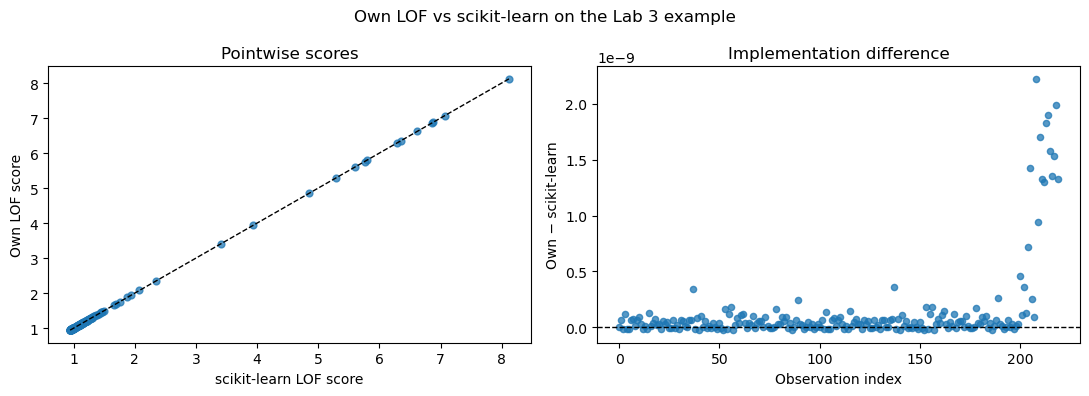

Spearman-like rank correlation (Pearson on ranks): 1.000
Mean absolute score difference: 0.0000


Global outliers: top-5% overlap — LOF/IF=9, LOF/hybrid=11


Different densities + local anomalies: top-5% overlap — LOF/IF=6, LOF/hybrid=16


Elongated group + boundary points: top-5% overlap — LOF/IF=10, LOF/hybrid=11


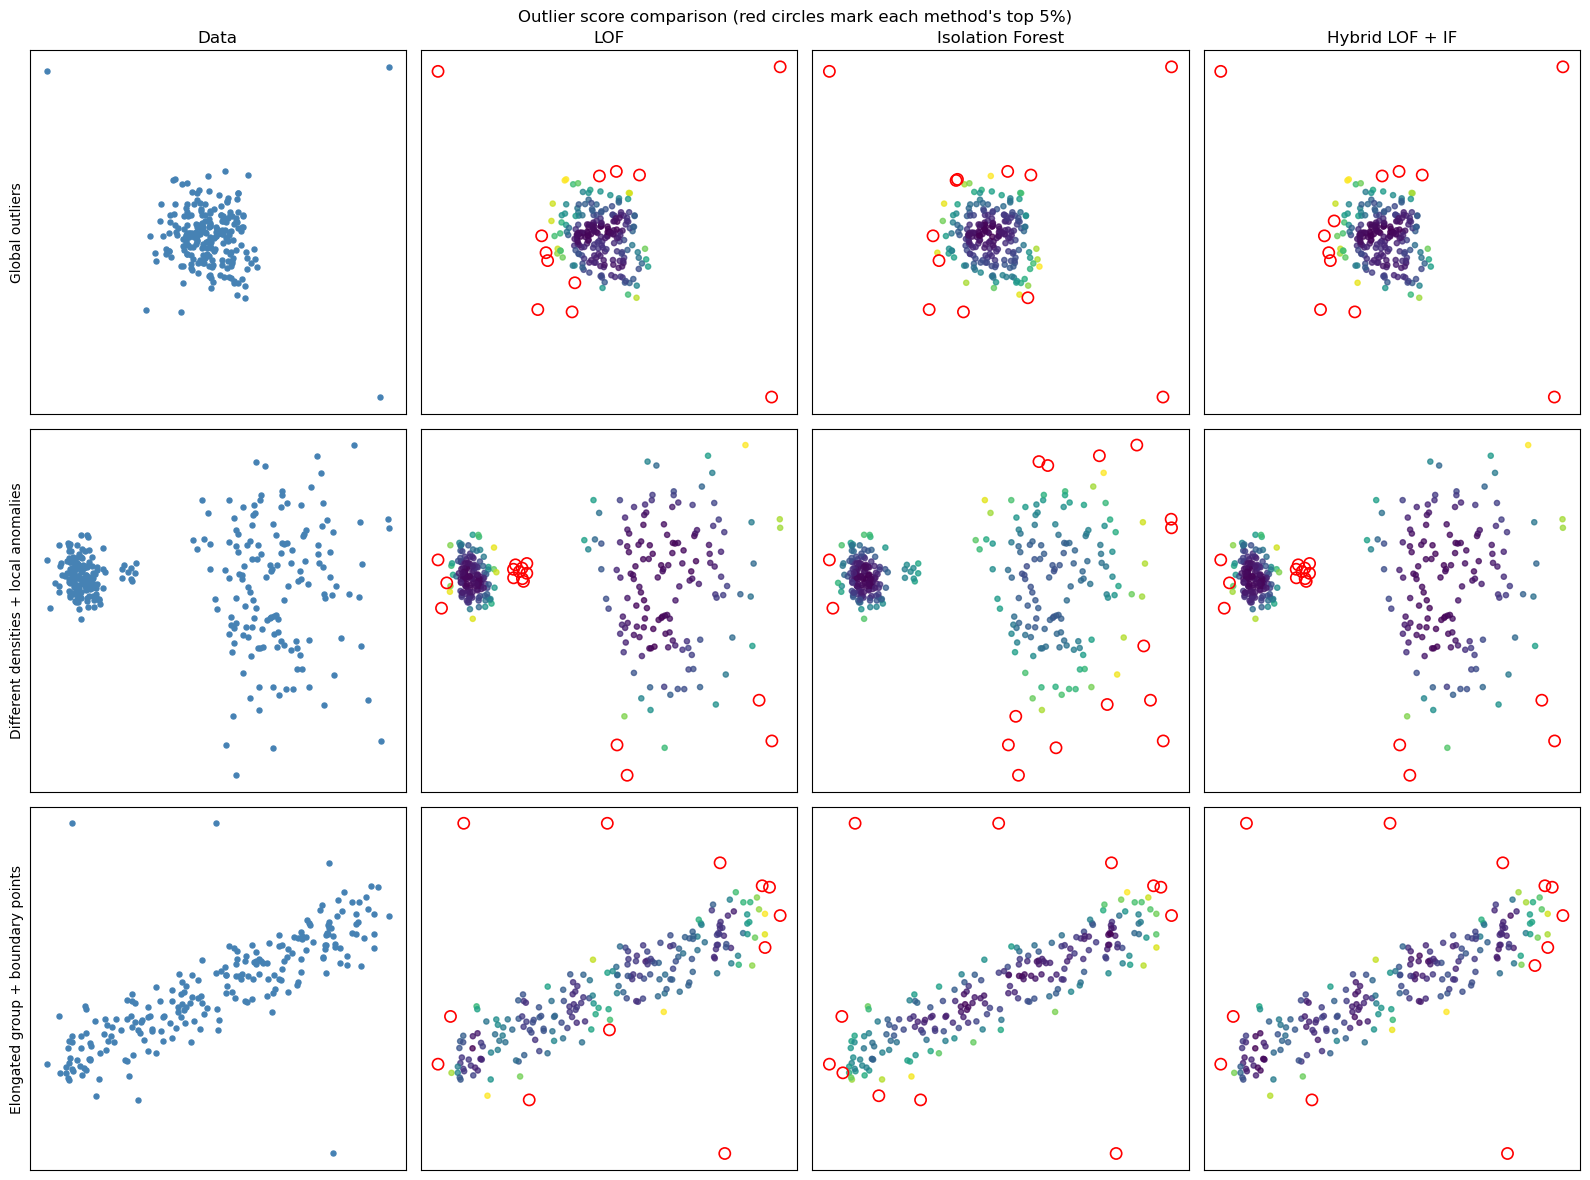

In [4]:
# Reproduce Lab 3, section 4.3, using its exact seeded data generation.
np.random.seed(42)
X_inliers = 0.3 * np.random.randn(100, 2)
X_inliers = np.r_[X_inliers + 2, X_inliers - 2]
X_outliers = np.random.uniform(low=-4, high=4, size=(20, 2))
X_lab3 = np.r_[X_inliers, X_outliers]
ground_truth = np.ones(len(X_lab3), dtype=int)
ground_truth[-len(X_outliers):] = -1

lof_own, lof_sklearn, lof_difference = compare_lof_implementations(
    X_lab3, k=20, title="Own LOF vs scikit-learn on the Lab 3 example"
)


# Compare LOF, Isolation Forest and the hybrid on several anomaly structures.
def make_examples(seed=9):
    rng = np.random.default_rng(seed)
    # Example 1: isolated global outliers among one compact population.
    global_data = rng.normal(0, 0.55, size=(220, 2))
    global_data = np.vstack([global_data, [[-3.8, 3.7], [4.0, -3.5], [4.2, 3.8]]])

    # Example 2: a compact and a diffuse population, plus local anomalies
    # near the compact population. The diffuse cluster is normal despite its
    # lower density, which is a known challenge for local methods.
    compact = rng.normal((-1.6, 0), 0.20, size=(150, 2))
    diffuse = rng.normal((1.8, 0), 0.78, size=(150, 2))
    local_anomalies = rng.normal((-0.75, 0.05), 0.07, size=(8, 2))
    varying_density = np.vstack([compact, diffuse, local_anomalies])

    # Example 3: an elongated normal group with a few points just outside
    # its dense boundary, illustrating sensitivity to neighborhood scale.
    t = rng.uniform(-2.5, 2.5, 220)
    elongated = np.column_stack([t + rng.normal(0, 0.10, 220),
                                 0.18 * t + rng.normal(0, 0.13, 220)])
    boundary = np.array([[0.0, 1.0], [1.8, -1.0], [-2.2, 1.0]])
    shape_data = np.vstack([elongated, boundary])
    return [global_data, varying_density, shape_data], [
        "Global outliers", "Different densities + local anomalies", "Elongated group + boundary points"
    ]


examples, example_titles = make_examples()
fig, axes = plt.subplots(len(examples), 4, figsize=(16, 12))
for row, (X, title) in enumerate(zip(examples, example_titles)):
    # sklearn score_samples is higher for normal points, so negate it.
    if_model = IsolationForest(n_estimators=300, contamination="auto", random_state=17)
    if_model.fit(X)
    if_score = -if_model.score_samples(X)
    lof_score = lof_scores(X, k=20)
    hybrid_score = hybrid_lof_if(X, if_score, k=20, alpha=0.8)
    scores = [None, lof_score, if_score, hybrid_score]
    names = ["Data", "LOF", "Isolation Forest", "Hybrid LOF + IF"]
    for col, (name, score) in enumerate(zip(names, scores)):
        ax = axes[row, col]
        if score is None:
            ax.scatter(X[:, 0], X[:, 1], s=13, color="steelblue")
        else:
            # Show the top 5% according to each method with red outlines.
            cutoff = np.quantile(score, 0.95)
            flagged = score >= cutoff
            ax.scatter(X[~flagged, 0], X[~flagged, 1], c=score[~flagged],
                       cmap="viridis", s=14, alpha=0.75)
            ax.scatter(X[flagged, 0], X[flagged, 1], facecolors="none",
                       edgecolors="red", s=65, linewidths=1.2)
        ax.set_title(name if row == 0 else "")
        if col == 0:
            ax.set_ylabel(title)
        ax.set_xticks([])
        ax.set_yticks([])
    print(f"{title}: top-5% overlap — LOF/IF={len(set(np.argsort(lof_score)[-int(np.ceil(.05*len(X))):]) & set(np.argsort(if_score)[-int(np.ceil(.05*len(X))):]))}, "
          f"LOF/hybrid={len(set(np.argsort(lof_score)[-int(np.ceil(.05*len(X))):]) & set(np.argsort(hybrid_score)[-int(np.ceil(.05*len(X))):]))}")
fig.suptitle("Outlier score comparison (red circles mark each method's top 5%)")
fig.tight_layout()
plt.show()


### c) Reading the demonstrations

The three examples show isolated global outliers, different-density groups with local anomalies, and an elongated group with boundary points. Red circles mark each method's top 5% for display; this is not an assumed real-world outlier rate. IF focuses on globally isolated points, while LOF compares local densities. The hybrid reduces the influence of neighbors that IF ranks as unusual, but it is not guaranteed to beat either method.

Here $k=20$ and $\alpha=0.8$. On the Lab 3 example, our LOF scores match scikit-learn (rank correlation 1.000, mean absolute difference 0). Across the three generated examples, LOF and IF share 9, 6, and 10 top-ranked points; LOF and the hybrid share 11, 16, and 11. These results describe only these samples.

Run this exercise with scikit-learn and Matplotlib installed.

## Exercise 3 - [20%]

Given a dataset $X = \{x_1,...,x_N\}$, $x_i \in \mathbb{R}^d$ and a distance measure computed by the function $dist(x_i, x_j) : X \times X \to \mathbb{R}$, one can define a procedure that *reweights* the distances as: 
$$
    dist'(x_i, x_j) = w_{ij} * dist(x_i, x_j)
$$
where $w_{ij} \in \mathbb{R}^+$. The aim is to bring datapoints that are related closer and to push further apart others that are less related. 

* **Kernels:** A typical low-level approach used is by employing a kernel, e.g. the RBF-kernel (radial basis function) 
    $$w_{ij} := 1 / (1+RBFkernel(x_i, x_j)) = 1 / (1 + \exp\{-\gamma \Vert x_i - x_j \Vert^2_2\})$$
where $\gamma = \frac{1}{2\sigma^2}$. 

* **Cluster-based:** Alternatively, cluster-based high-level approaches can be employed. The idea is that data clustering could determine a better $w_{ij}$. 
    * Flat clustering (e.g. $k$-means): Generate one or more clustering results and compute the frequency the two datapoints $x_i$ and $x_j$ get clustered together. 
    * Hierarchical clustering (e.g. HAC or bisecting $k$-means): Given the learned cluster hierarchy, we could define the proximity between two datapoints $x_i$ and $x_j$ based on the depth in the hierarchy (let that be $h_{ij}$) at which they get separated. 
    * Incremental clustering (e.g. global $k$-means): (deliberately not explained how this would work).

* **Random-Forest-based:** The idea here is to exploit the results of a Random Forest to estimate the $w_{ij}$ weights (see Fig. 1 in [1]). 

For this exercise, you will need to: 

**a)** Implement the above concepts and approaches: the simple kernel-based approach, the three cluster-based approaches, and the RF-based one. For the incremental clustering one, you will need to devise a way to build a meaningful measure.

**b)** Use generated synthetic data, similarly to what the previous exercise asks, to demonstrate the correctness of your implementation and the behavior of the approaches. Show results step-wise regarding the incremental steps to validate that your implementation works as expected.

**References:**  
[1] S. Athey et al. [Generalized random forests](https://arxiv.org/pdf/1610.01271), Annals of Statistics, 2019.

## Exercise 3 — Pairwise distance reweighting

### a) Weight constructions

For each method, I build a symmetric positive weight matrix and set $d'_{ij}=w_{ij}d_{ij}$. Similar pairs get a smaller multiplier. I use $w_{ij}=1/(1+s_{ij})$, where $s_{ij}\in[0,1]$ is the similarity.

1. **RBF:** $s_{ij}=\exp(-\gamma d_{ij}^2)$, with $\gamma=1/(2\sigma^2)$.
2. **Flat clustering:** run k-means with several initializations; similarity is the fraction of runs that put the pair together.
3. **Hierarchical:** convert the dendrogram merge height (cophenetic distance) to similarity with $s_{ij}=\exp(-d^{cophenetic}_{ij}/m)$, where $m$ is its median positive value.
4. **Incremental:** run global k-means as $k$ grows. Similarity is higher for pairs that stay together longer: $s_{ij}=\min(1,(k_{split}-1)/(K-1))$.
5. **Random Forest:** train a forest on k-means pseudo-labels. Similarity is the fraction of trees where the pair reaches the same leaf. The result depends on the pseudo-labels, so it may inherit their errors.

### b) Synthetic-data demonstration

The experiment creates three Gaussian groups, builds all five weight matrices, and compares within-group and between-group distances. The known labels are used only for this final comparison, not to build the weights.

### Distance-weight functions

The functions use explicit loops for the pairwise calculations, so the steps are easy to follow. This also makes them slow on larger datasets.

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.ensemble import RandomForestClassifier


def euclidean_distances(X):
    n = len(X)
    distances = np.zeros((n, n))
    for i in range(n):
        for j in range(n):
            difference = X[i] - X[j]
            distances[i, j] = np.sqrt(np.sum(difference ** 2))
    return distances


def similarity_to_weights(S):
    """Map similarities in [0,1] to positive distance multipliers in [0.5,1]."""
    n = len(S)
    W = np.ones((n, n))
    for i in range(n):
        for j in range(n):
            similarity = (S[i, j] + S[j, i]) / 2.0
            similarity = min(1.0, max(0.0, similarity))
            if i != j:
                W[i, j] = 1.0 / (1.0 + similarity)
    return W


def rbf_weights(D, sigma=0.8):
    gamma = 1.0 / (2.0 * sigma**2)
    n = len(D)
    S = np.zeros((n, n))
    for i in range(n):
        for j in range(n):
            S[i, j] = np.exp(-gamma * D[i, j] ** 2)
    return similarity_to_weights(S), S


def flat_cluster_weights(X, k=3, n_runs=25, seed=0):
    n = len(X)
    co_clustered = np.zeros((n, n), dtype=float)
    for run in range(n_runs):
        model = KMeans(n_clusters=k, n_init=1, random_state=seed + run)
        labels = model.fit_predict(X)
        for i in range(n):
            for j in range(n):
                if labels[i] == labels[j]:
                    co_clustered[i, j] += 1
    S = co_clustered / n_runs
    return similarity_to_weights(S), S


def hierarchical_weights(X):
    """Use normalized cophenetic merge heights as a tree-based similarity."""
    n = len(X)
    model = AgglomerativeClustering(
        n_clusters=None, distance_threshold=0, linkage="average",
        compute_full_tree=True, compute_distances=True
    ).fit(X)
    cophenetic = np.zeros((n, n), dtype=float)
    # Each internal node joins two child subtrees. Every cross-child leaf pair
    # first meets at this node, so its cophenetic distance is this merge height.
    leaves = {i: [i] for i in range(n)}
    for merge_id, (left, right) in enumerate(model.children_):
        node_id = n + merge_id
        left_leaves, right_leaves = leaves[left], leaves[right]
        height = model.distances_[merge_id]
        for i in left_leaves:
            for j in right_leaves:
                cophenetic[i, j] = height
                cophenetic[j, i] = height
        leaves[node_id] = left_leaves + right_leaves
    positive = cophenetic[cophenetic > 0]
    scale = np.median(positive) if positive.size else 1.0
    S = np.zeros((n, n))
    for i in range(n):
        for j in range(n):
            S[i, j] = np.exp(-cophenetic[i, j] / max(scale, 1e-12))
    for i in range(n):
        S[i, i] = 1.0
    return similarity_to_weights(S), S, cophenetic


def lloyd_from_centers(X, centers, max_iter=60, tol=1e-5):
    """Small Lloyd implementation used for reproducible global k-means trials."""
    centers = np.asarray(centers, dtype=float).copy()
    for _ in range(max_iter):
        squared = np.sum((X[:, None, :] - centers[None, :, :])**2, axis=2)
        labels = np.argmin(squared, axis=1)
        new_centers = centers.copy()
        for j in range(len(centers)):
            members = X[labels == j]
            if len(members):
                new_centers[j] = members.mean(axis=0)
        if np.max(np.linalg.norm(new_centers - centers, axis=1)) < tol:
            centers = new_centers
            break
        centers = new_centers
    squared = np.sum((X[:, None, :] - centers[None, :, :])**2, axis=2)
    labels = np.argmin(squared, axis=1)
    inertia = float(np.sum(np.min(squared, axis=1)))
    return centers, labels, inertia


def greedy_global_kmeans_sequence(X, k_max=5):
    """Greedy global k-means: test every observation as the next center."""
    X = np.asarray(X, dtype=float)
    centers = X.mean(axis=0, keepdims=True)
    centers, labels, inertia = lloyd_from_centers(X, centers)
    solutions = [(centers.copy(), labels.copy(), inertia)]
    diagnostics = [{"k": 1, "candidate_index": None, "inertia": inertia}]

    for k in range(2, k_max + 1):
        best = None
        for candidate_idx in range(len(X)):
            init = np.vstack([centers, X[candidate_idx]])
            trial = lloyd_from_centers(X, init)
            if best is None or trial[2] < best[2]:
                best = trial
                best_idx = candidate_idx
        centers, labels, inertia = best
        solutions.append((centers.copy(), labels.copy(), inertia))
        diagnostics.append({"k": k, "candidate_index": int(best_idx), "inertia": inertia})
    return solutions, diagnostics


def incremental_weights(X, k_max=5):
    solutions, diagnostics = greedy_global_kmeans_sequence(X, k_max=k_max)
    n = len(X)
    # Record the first number of clusters that separates each pair.
    split_at = np.full((n, n), k_max + 1, dtype=int)
    for i in range(n):
        split_at[i, i] = 1

    for k, (_, labels, _) in enumerate(solutions, start=1):
        for i in range(n):
            for j in range(n):
                if split_at[i, j] == k_max + 1 and labels[i] != labels[j]:
                    split_at[i, j] = k

    # Pairs that split later get a larger similarity.
    S = np.zeros((n, n))
    for i in range(n):
        for j in range(n):
            if i == j:
                S[i, j] = 1.0
            else:
                S[i, j] = min(1.0, (split_at[i, j] - 1) / (k_max - 1))
    return similarity_to_weights(S), S, solutions, diagnostics


def random_forest_weights(X, k=3, seed=0):
    """Forest leaf co-occurrence proximity from k-means pseudo-labels."""
    pseudo_labels = KMeans(n_clusters=k, n_init=10, random_state=seed).fit_predict(X)
    forest = RandomForestClassifier(
        n_estimators=200, min_samples_leaf=2, max_features="sqrt",
        random_state=seed, n_jobs=-1
    ).fit(X, pseudo_labels)
    leaves = forest.apply(X)  # rows are observations, columns are trees
    n, n_trees = leaves.shape
    S = np.zeros((n, n))
    for i in range(n):
        for j in range(n):
            same_leaf_count = 0
            for tree in range(n_trees):
                if leaves[i, tree] == leaves[j, tree]:
                    same_leaf_count += 1
            S[i, j] = same_leaf_count / n_trees
    return similarity_to_weights(S), S, pseudo_labels


### Apply the methods to synthetic data


Greedy global k-means steps (candidate is the observation used to initialize the added center):
{'k': 1, 'candidate_index': None, 'inertia': 686.2259895772813}
{'k': 2, 'candidate_index': 0, 'inertia': 324.86956374831016}
{'k': 3, 'candidate_index': 5, 'inertia': 52.07394785925301}
{'k': 4, 'candidate_index': 94, 'inertia': 44.053769048174445}
{'k': 5, 'candidate_index': 46, 'inertia': 37.14238818189715}


/var/folders/99/m1fr9wy91rn6rsxlkjr96t300000gp/T/ipykernel_95744/3165959828.py:36: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


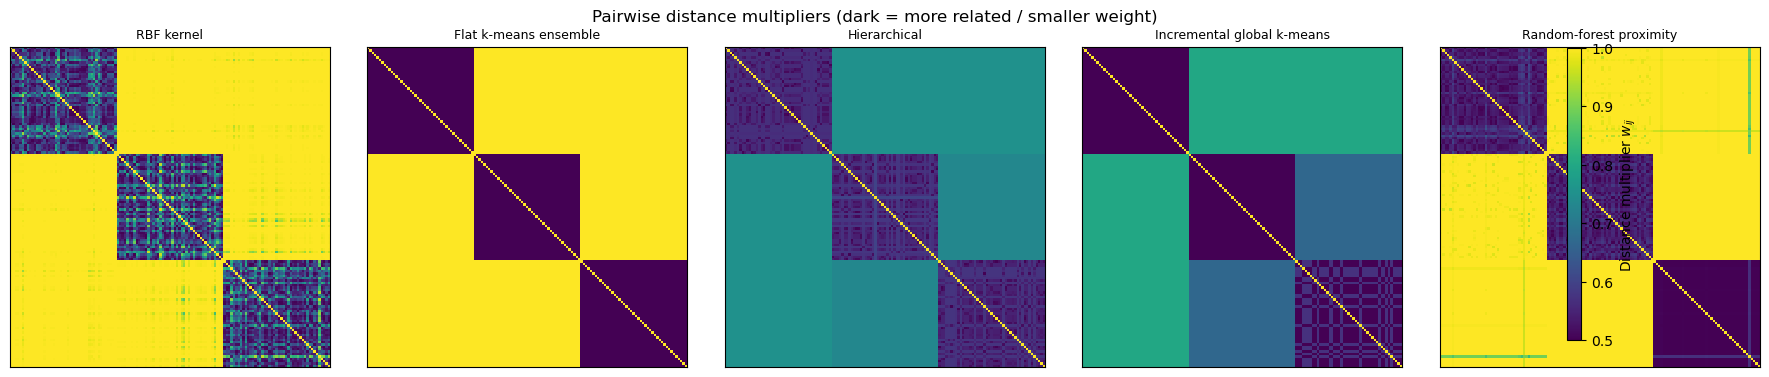

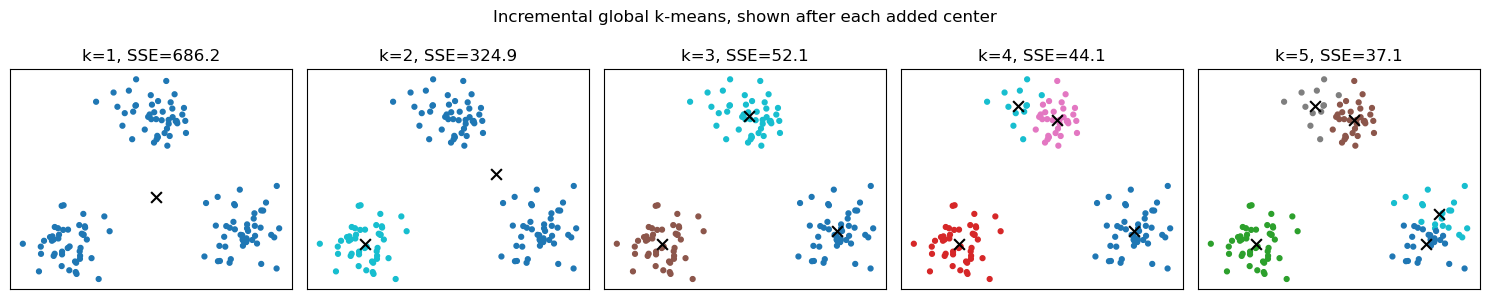


Weighted-distance summary (median over point pairs):
RBF kernel                   within=0.429  between=3.806
Flat k-means ensemble        within=0.368  between=3.806
Hierarchical                 within=0.410  between=2.842
Incremental global k-means   within=0.370  between=2.909
Random-forest proximity      within=0.385  between=3.801


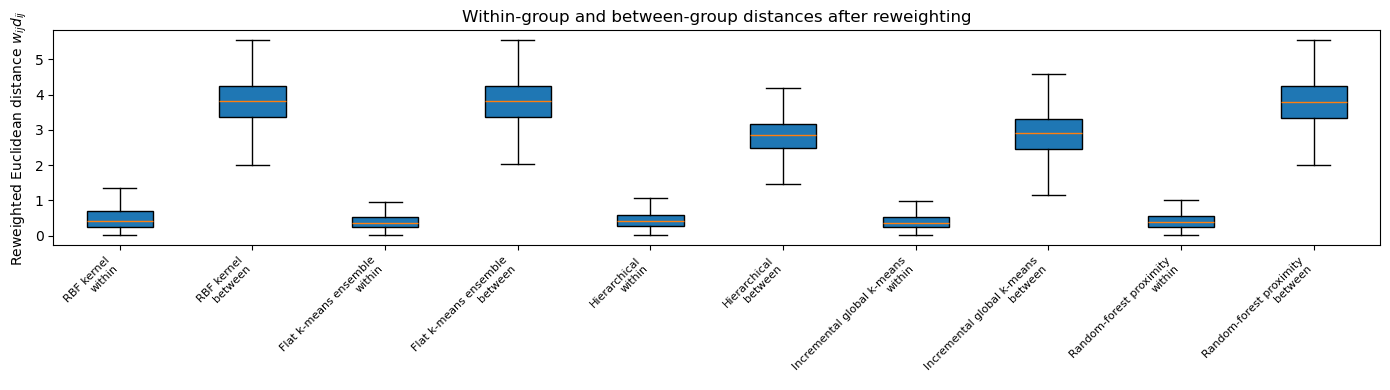

In [6]:
# Reproducible 2D data: labels are retained only for the post-hoc evaluation.
rng = np.random.default_rng(31)
centers_true = np.array([[-2.0, -1.0], [2.0, -0.8], [0.0, 2.0]])
X_parts = [rng.normal(loc=mu, scale=0.48, size=(45, 2)) for mu in centers_true]
X_demo = np.vstack(X_parts)
y_demo = np.repeat(np.arange(3), 45)
D = euclidean_distances(X_demo)

W_rbf, S_rbf = rbf_weights(D, sigma=0.9)
W_flat, S_flat = flat_cluster_weights(X_demo, k=3, n_runs=25, seed=10)
W_hier, S_hier, cophenetic = hierarchical_weights(X_demo)
W_inc, S_inc, inc_solutions, inc_diagnostics = incremental_weights(X_demo, k_max=5)
W_rf, S_rf, rf_pseudo_labels = random_forest_weights(X_demo, k=3, seed=10)

methods = {
    "RBF kernel": W_rbf,
    "Flat k-means ensemble": W_flat,
    "Hierarchical": W_hier,
    "Incremental global k-means": W_inc,
    "Random-forest proximity": W_rf,
}

# Stepwise view: show how global k-means changes from one to five centers.
print("Greedy global k-means steps (candidate is the observation used to initialize the added center):")
for row in inc_diagnostics:
    print(row)

fig, axes = plt.subplots(1, 5, figsize=(18, 3.8))
for ax, (name, W) in zip(axes, methods.items()):
    im = ax.imshow(W, cmap="viridis", vmin=0.5, vmax=1.0, interpolation="nearest")
    ax.set_title(name, fontsize=9)
    ax.set_xticks([])
    ax.set_yticks([])
fig.colorbar(im, ax=axes, fraction=0.02, pad=0.02, label="Distance multiplier $w_{ij}$")
fig.suptitle("Pairwise distance multipliers (dark = more related / smaller weight)")
fig.tight_layout()
plt.show()

# Inspect incremental assignments and error at each intermediate k.
fig, axes = plt.subplots(1, len(inc_solutions), figsize=(15, 3))
for k, ((centers_k, labels_k, inertia_k), ax) in enumerate(zip(inc_solutions, axes), start=1):
    ax.scatter(X_demo[:, 0], X_demo[:, 1], c=labels_k, cmap="tab10", s=12)
    ax.scatter(centers_k[:, 0], centers_k[:, 1], marker="x", c="black", s=60)
    ax.set_title(f"k={k}, SSE={inertia_k:.1f}")
    ax.set_xticks([])
    ax.set_yticks([])
fig.suptitle("Incremental global k-means, shown after each added center")
fig.tight_layout()
plt.show()

# Compare distributions of reweighted distances for known same/different groups.
same_group = y_demo[:, None] == y_demo[None, :]
upper = np.triu(np.ones_like(same_group, dtype=bool), k=1)
within = upper & same_group
between = upper & ~same_group
labels_box, values_box = [], []
print("\nWeighted-distance summary (median over point pairs):")
for name, W in methods.items():
    D_prime = W * D
    w_med = float(np.median(D_prime[within]))
    b_med = float(np.median(D_prime[between]))
    print(f"{name:28s} within={w_med:.3f}  between={b_med:.3f}")
    values_box.extend([D_prime[within], D_prime[between]])
    labels_box.extend([name + "\nwithin", name + "\nbetween"])

fig, ax = plt.subplots(figsize=(14, 4))
ax.boxplot(values_box, showfliers=False, patch_artist=True)
ax.set_xticks(np.arange(1, len(labels_box) + 1), labels_box, rotation=45, ha="right", fontsize=8)
ax.set_ylabel("Reweighted Euclidean distance $w_{ij}d_{ij}$")
ax.set_title("Within-group and between-group distances after reweighting")
fig.tight_layout()
plt.show()


### Interpretation

Global k-means SSE falls from 686.23 at $k=1$ to 324.87, 52.07, 44.05, and 37.14 at $k=2,3,4,5$. The plots show each intermediate clustering.

The median within/between reweighted distances are: RBF 0.429/3.806, flat 0.368/3.806, hierarchy 0.410/2.842, incremental 0.370/2.909, and Random Forest 0.385/3.801. All methods keep a clear gap on this well-separated example. The exact values differ because each method assigns different weights.

Pairwise calculations use memory proportional to $N^2$, and greedy global tests every point at each step. That is why the example is small. The forest uses k-means pseudo-labels and can inherit their mistakes. The RF proximity follows the idea in Athey et al., [Generalized Random Forests](https://arxiv.org/pdf/1610.01271).

## Exercise 4 - [40%]

As opposed to bottom-up clustering approaches, a top-down method starts with one cluster -a model with one component- and tries incrementally to increase the number of clusters by introducing and fitting more components in the model. The general algorithm goes as follows:

* **Initialization:** start with a $k=1$ component model, $M_k$
* **Step 1:** fit the model $M_k$
* **Step 2:** find a good way to introduce and initialize a new component; set $k=k+1$ and go to Step 1 

There are many ways to make more specific the steps of this process. 

**Model:** one can pick a cluster model, e.g. a centroid-based like that of $k$-means, or a probabilistic model like the Gaussian Mixture Models (GMM). In both cases an iterative approach takes place when fitting such a model.

**Incremental step:** Most importantly, one needs to decide about how Step 2 operates. Indicative options originally expressed using $k$-means are:
* **Bisecting:** This approach chooses one cluster and splits it in two parts. The criterion of which cluster to pick varies; one simple way is to choose the cluster with the largest error (or average error). In the case of $k$-means, which uses a hard assignment of points to clusters, this is: 
    - B1) Initialize a second centroid using a random point of the cluster.
    - B2) Run a 2-means inside the cluster using only the points of that cluster. 
    - B3) (Optionally) A full $k$-means fine-tuning to update all the $k+1$ clusters can be performed. 
    Note that, if step B3 is not involved, 2 of the centroids are the product of the cluster splitting, while the rest come untouched from the previous $k$-order solution.
* **Global:** In its greedy version (see if needed [1]), this approach examines as the ($k+1$)-th centroid each of the $N$ points of the dataset, and in each case it fits a different $k+1$ model with ($k+1$)-means. Out of all the $N$ trials, it chooses the model that produced the maximal reduction of the clustering error (in fact it doesn't need to store the models, but only to rerun the best case found).
* **Fast Global:** It is a variation of Global $k$-means that initializes the $k+1$-th centroid with the point that achieves the largest reduction of error only after one $k$-means update, i.e. after considering it as new centroid and looking which other points would be assigned to that new cluster, and without iterating further till convergence.
* **Global++:** Instead of checking all $N$ points as candidates for initializing the $k+1$-th centroid, here the $k$-means++ principle is used. Specifically, the $k+1$ centroid is initialized by choosing at random one point based on the distribution that is proportional to the squared distance of each point to its nearest among the $k$ computed centroids (i.e. the $D^2$ distribution of $k$-means++). This should be repeated $m<N$ times (where $m$ is a parameter, e.g. $m=\lfloor 0.1*N \rfloor$) and pick the best choice.

**$k$-means++ and improvements:** At each incremental step, having $k$ already selected seeds, the algorithm selects the new ($k+1$)-th seed according to the distribution $\Delta_k$ induced by the squared distance of a candidate to its nearest among those $k$ seeds. Aiming to improve the selection of the new seed, there can be -at least- two directions: 
- i) *Extending the local search*. Considering that each time the seed set at the $k+1$ step is in the "neighborhood" of the seed set of the previous step (i.e. the same set plus one more element), then extending the local search means that we allow the search to examine seed sets that are more different to that of the previous step. This can be achieved by swapping one or more of the already selected seeds with other unselected data objects. See mainly [3], but also the more complicated [4] for multiple swaps.
- ii) *Combining external information*. The information encoded in $\Delta$ can be combined with external information that comes from a preprocessing step.

**Recipe to prepare**

Consider that the final number of clusters $k^*$ is known in each case. First, use $k$-means as base algorithm, then extend to GMM as described below.

**a)** Which property of the solution produced by the bisecting variation does not hold any more, when including Step B3 and after applying it? Compare with the global incremental approach with regard to the same property.

**b)** Implement the bisecting variation using $k$-means as base algorithm, in both versions: without and with the optional Step B3.

**c)** Implement the greedy global incremental, the fast global, and the global++ variations.

**d)** Aiming to improve $k$-means++, modify the seed selection step by combining $\Delta$ with information from a random-forest-based proximity measure (see Random-Forest-based in Exercise 3) that is computed in a preprocessing step. Try also (both combined and independently) the swapping approach suggested in [3].

**e)** Run experiments with all your $k$-means variants for the color clustering application we saw in the course (with given $k^*$ as in that example).

**f)** Now, extend your toolbox by also considering the GMM as base algorithm. You will need a piece of code implementing the GMM training with a fixed $k$ using the Expectation-Maximization (EM) algorithm. 

**g)** What is the main problem of applying the bisecting principle in the GMM case? Find a heuristic workaround to adapt it to this probabilistic cluster model.

**h)** Construct a random synthetic dataset as follows. Consider a 5-by-5 2D grid arrangement of 25 clusters: i.e. the mean of the 1st cluster will be at (0,4), the 2nd at (1,4),..., the 5th at (4,4), the 6th at (0,3),..., the 25th at (4,0). Each cluster will have $n_k=50$ points in 2D generated by a Gaussian distribution, with fixed $\sigma$ for all clusters (test values $\sigma \in \{0.1, 0.5, 0.7, 1\}$). Run experiments with all your implementations (i.e. the flat and incremental $k$-means variants; flat GMM training with fixed $k$; incremental GMM training with bisecting splits; incremental GMM training based on the global principle). Provide summaries of results about the clustering error and detailed comments with your observations/interpretations about the performance of the methods.

**References:**  
[1] A. Likas et al. [The global $k$-means clustering algorithm](https://hal.inria.fr/inria-00321515/document), Pattern Recognition, 2003.  
[2] G. Vardakas et al. [Global $k$-means++: an effective relaxation of the global $k$-means clustering algorithm](https://arxiv.org/pdf/2211.12271), Applied Intelligence, 2024.  
[3] S. Lattanzi et al. [A Better $k$-means++ Algorithm via Local Search](https://proceedings.mlr.press/v97/lattanzi19a/lattanzi19a.pdf), ICML, 2019.  
[4] L. Beretta et al. [Multi-swap $k$-means++](https://proceedings.neurips.cc/paper_files/paper/2023/file/52d63f9e4b81f866bf69fb3c834aad47-Paper-Conference.pdf), NeurIPS, 2023.

## Exercise 4 — Incremental clustering

### a) Refinement property

Without B3, bisecting k-means splits one cluster and leaves the others alone. Each new partition is a refinement of the previous one. B3 refits all centers, so points can move across old cluster boundaries and the refinement property is lost. Greedy global k-means can also reassign points anywhere.

### b–d) k-means variants

The code implements bisecting k-means with and without B3, greedy global, fast global, and global++. It also tests ordinary k-means++ seeding, Random-Forest-adjusted $D^2$ seeding, swaps, and forest seeding plus swaps. The forest is trained on k-means pseudo-labels; its proximity adjusts the chance of choosing a new seed.

### e) Color clustering

Lab 4 uses the Summer Palace image `china.jpg` with $k^*=64$. I fit on a seeded sample of 500 pixels (the lab uses 1,000) to reduce runtime, then apply the centers to the full image.

### f–g) GMM and bisecting

The code trains full-covariance GMMs with EM. A hard split does not transfer directly: GMM assignments are soft, and splitting one component affects the whole mixture. The heuristic splits the component with the largest weighted covariance along its main direction, then refits the full model with EM.

### h) 5-by-5 Gaussian grid

The experiment uses 25 clusters with 50 points each and all four requested $\sigma$ values. It compares flat and incremental k-means, flat GMM, bisecting GMM, and global GMM. Greedy and fast global k-means test all 1,250 points at each step; global++ tests 125. Global GMM also tests all 1,250 candidate means, fitting candidates in batches with EM. The grid runs use up to 15 Lloyd updates and 8 EM updates. Results show SSE and ARI, plus NLL for GMM.

#### K-means functions

The cell defines the center updates, initializations, and bisecting/global methods.

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import adjusted_rand_score


def sqdist_to_centers(X, centers):
    return np.sum((X[:, None, :] - centers[None, :, :]) ** 2, axis=2)


def lloyd_kmeans(X, initial_centers, max_iter=50, tol=1e-4):
    """Run Lloyd k-means from the supplied starting centers."""
    X = np.asarray(X, dtype=float)
    centers = np.asarray(initial_centers, dtype=float).copy()
    for _ in range(max_iter):
        labels = np.argmin(sqdist_to_centers(X, centers), axis=1)
        updated = centers.copy()
        for j in range(len(centers)):
            members = X[labels == j]
            if len(members):
                updated[j] = members.mean(axis=0)
        if np.max(np.linalg.norm(updated - centers, axis=1)) < tol:
            centers = updated
            break
        centers = updated
    distances = sqdist_to_centers(X, centers)
    labels = np.argmin(distances, axis=1)
    return centers, labels, float(np.sum(np.min(distances, axis=1)))


def d2_sample(X, centers, rng, size):
    nearest_d2 = np.min(sqdist_to_centers(X, centers), axis=1)
    probs = nearest_d2.copy()
    probs[~np.isfinite(probs)] = 0
    if probs.sum() <= 1e-12:
        probs = np.ones(len(X), dtype=float)
    probs /= probs.sum()
    size = min(size, len(X))
    return rng.choice(len(X), size=size, replace=False, p=probs)


def kmeanspp_seeds(X, k, rng, proximity=None):
    """Choose starting centers with D-squared sampling."""
    X = np.asarray(X, dtype=float)
    seed_ids = [int(rng.integers(len(X)))]
    while len(seed_ids) < k:
        nearest_d2 = np.min(sqdist_to_centers(X, X[seed_ids]), axis=1)
        if proximity is not None:
            max_proximity = np.max(proximity[:, seed_ids], axis=1)
            novelty = 0.15 + (1.0 - max_proximity)
            nearest_d2 = nearest_d2 * novelty
        nearest_d2[seed_ids] = 0
        if nearest_d2.sum() <= 1e-12:
            candidates = np.setdiff1d(np.arange(len(X)), seed_ids)
            chosen = int(rng.choice(candidates))
        else:
            chosen = int(rng.choice(len(X), p=nearest_d2 / nearest_d2.sum()))
        seed_ids.append(chosen)
    return X[seed_ids].copy()


def rf_leaf_proximity(X, k_pseudo=4, n_trees=60, seed=0):
    """Estimate similarity by how often two points share a forest leaf."""
    pseudo = KMeans(n_clusters=k_pseudo, n_init=5, random_state=seed).fit_predict(X)
    forest = RandomForestClassifier(
        n_estimators=n_trees, min_samples_leaf=2, max_features="sqrt",
        random_state=seed, n_jobs=1
    ).fit(X, pseudo)
    leaves = forest.apply(X)
    n, trees = leaves.shape
    proximity = np.zeros((n, n), dtype=float)
    for t in range(trees):
        lt = leaves[:, t]
        proximity += (lt[:, None] == lt[None, :])
    proximity /= trees
    return proximity


def fit_kmeans(X, k, seed=0, n_restarts=1, proximity=None, swap_rounds=0,
               swap_candidates=10, max_iter=50):
    """Run k-means++ (optionally RF-adjusted and/or locally swapped)."""
    X = np.asarray(X, dtype=float)
    rng = np.random.default_rng(seed)
    best = None
    for _ in range(n_restarts):
        centers = kmeanspp_seeds(X, k, rng, proximity=proximity)
        # Local search: try replacing selected seeds with high-residual points.
        for _round in range(swap_rounds):
            labels = np.argmin(sqdist_to_centers(X, centers), axis=1)
            residual = np.min(sqdist_to_centers(X, centers), axis=1)
            candidates = np.argsort(residual)[-min(swap_candidates, len(X)):]
            current_obj = float(residual.sum())
            best_obj, best_swap = current_obj, None
            for j in range(k):
                for candidate in candidates:
                    if np.min(np.sum((centers - X[candidate])**2, axis=1)) < 1e-12:
                        continue
                    trial = centers.copy()
                    trial[j] = X[candidate]
                    obj = float(np.sum(np.min(sqdist_to_centers(X, trial), axis=1)))
                    if obj + 1e-9 < best_obj:
                        best_obj, best_swap = obj, trial
            if best_swap is None:
                break
            centers = best_swap
        result = lloyd_kmeans(X, centers, max_iter=max_iter)
        if best is None or result[2] < best[2]:
            best = result
    return best


def bisecting_kmeans(X, k_target, with_B3=False, seed=0):
    """Split the cluster with the largest error; optionally run B3."""
    X = np.asarray(X, dtype=float)
    centers = X.mean(axis=0, keepdims=True)
    labels = np.zeros(len(X), dtype=int)
    rng = np.random.default_rng(seed)
    for k in range(2, k_target + 1):
        errors = []
        for j in range(k - 1):
            ids = np.flatnonzero(labels == j)
            errors.append(float(np.sum((X[ids] - centers[j])**2)) if len(ids) else -1)
        chosen = int(np.argmax(errors))
        ids = np.flatnonzero(labels == chosen)
        local_init = kmeanspp_seeds(X[ids], 2, rng)
        local_centers, local_labels, _ = lloyd_kmeans(X[ids], local_init)
        centers[chosen] = local_centers[0]
        centers = np.vstack([centers, local_centers[1]])
        labels[ids[local_labels == 0]] = chosen
        labels[ids[local_labels == 1]] = k - 1
        # Recompute means for the split children.
        for j in (chosen, k - 1):
            members = X[labels == j]
            if len(members): centers[j] = members.mean(axis=0)
        if with_B3:
            centers, labels, sse = lloyd_kmeans(X, centers)
        else:
            sse = float(np.sum((X - centers[labels])**2))
    return centers, labels, float(np.sum((X - centers[labels])**2))



def lloyd_many(X, initial_centers, max_iter=50, tol=1e-4):
    """Run Lloyd updates for several starting center sets at once."""
    centers = initial_centers.copy()
    n_models = len(centers)
    active = np.ones(n_models, dtype=bool)

    x_squared = np.sum(X ** 2, axis=1)[None, :, None]

    for _ in range(max_iter):
        center_squared = np.sum(centers ** 2, axis=2)[:, None, :]
        cross_products = np.matmul(centers, X.T).transpose(0, 2, 1)
        distances = x_squared + center_squared - 2 * cross_products
        distances = np.maximum(distances, 0)
        labels = np.argmin(distances, axis=2)
        updated = centers.copy()

        for j in range(centers.shape[1]):
            members = labels == j
            counts = members.sum(axis=1)
            sums = np.sum(X[None, :, :] * members[:, :, None], axis=1)
            has_members = counts > 0
            updated[has_members, j] = sums[has_members] / counts[has_members, None]

        movement = np.linalg.norm(updated - centers, axis=2).max(axis=1)
        centers[active] = updated[active]
        active = active & (movement >= tol)
        if not np.any(active):
            break

    center_squared = np.sum(centers ** 2, axis=2)[:, None, :]
    cross_products = np.matmul(centers, X.T).transpose(0, 2, 1)
    distances = x_squared + center_squared - 2 * cross_products
    distances = np.maximum(distances, 0)
    labels = np.argmin(distances, axis=2)
    errors = np.sum(np.min(distances, axis=2), axis=1)
    return centers, labels, errors

def greedy_global_kmeans(X, k_target, max_iter=50):
    X = np.asarray(X, dtype=float)
    centers, labels, sse = lloyd_kmeans(X, X.mean(axis=0, keepdims=True), max_iter=max_iter)
    batch_size = 128

    for k in range(2, k_target + 1):
        current_centers = centers.copy()
        best_sse = np.inf
        best_centers = None
        best_labels = None
        for start in range(0, len(X), batch_size):
            candidate_ids = np.arange(start, min(start + batch_size, len(X)))
            old_centers = np.repeat(current_centers[None, :, :], len(candidate_ids), axis=0)
            trial_centers = np.concatenate([old_centers, X[candidate_ids, None, :]], axis=1)
            new_centers, new_labels, errors = lloyd_many(X, trial_centers, max_iter=max_iter)
            best_in_batch = int(np.argmin(errors))
            if errors[best_in_batch] < best_sse:
                best_sse = errors[best_in_batch]
                best_centers = new_centers[best_in_batch]
                best_labels = new_labels[best_in_batch]

        centers, labels, sse = best_centers, best_labels, best_sse

    return centers, labels, float(sse)


def fast_global_kmeans(X, k_target, max_iter=50):
    X = np.asarray(X, dtype=float)
    centers, labels, sse = lloyd_kmeans(X, X.mean(axis=0, keepdims=True), max_iter=max_iter)
    batch_size = 128

    for k in range(2, k_target + 1):
        best_sse = np.inf
        best_centers = None
        for start in range(0, len(X), batch_size):
            candidate_ids = np.arange(start, min(start + batch_size, len(X)))
            old_centers = np.repeat(centers[None, :, :], len(candidate_ids), axis=0)
            trial_centers = np.concatenate([old_centers, X[candidate_ids, None, :]], axis=1)
            new_centers, _, errors = lloyd_many(X, trial_centers, max_iter=1)
            best_in_batch = int(np.argmin(errors))
            if errors[best_in_batch] < best_sse:
                best_sse = errors[best_in_batch]
                best_centers = new_centers[best_in_batch]

        centers, labels, sse = lloyd_kmeans(X, best_centers, max_iter=max_iter)

    return centers, labels, sse


def globalpp_kmeans(X, k_target, m=10, seed=0, max_iter=50):
    """Try m candidates sampled with probability based on squared distance."""
    X = np.asarray(X, dtype=float)
    rng = np.random.default_rng(seed)
    centers, labels, sse = lloyd_kmeans(X, X.mean(axis=0, keepdims=True), max_iter=max_iter)
    for k in range(2, k_target + 1):
        ids = d2_sample(X, centers, rng, size=min(m, len(X)))
        best = None
        for idx in ids:
            trial = lloyd_kmeans(X, np.vstack([centers, X[idx]]), max_iter=max_iter)
            if best is None or trial[2] < best[2]: best, best_idx = trial, int(idx)
        centers, labels, sse = best
    return centers, labels, sse


#### GMM and EM

The EM code alternates between estimating component memberships and updating the Gaussians. The bisecting version splits a component, then refits the full mixture.

In [8]:
def logsumexp(A, axis=1):
    m = np.max(A, axis=axis, keepdims=True)
    return np.squeeze(m, axis=axis) + np.log(np.sum(np.exp(A - m), axis=axis))


def gmm_log_prob(X, means, covariances, weights, reg=1e-5):
    n, d = X.shape
    covariances = covariances + reg * np.eye(d)
    inverse_covariances = np.linalg.inv(covariances)
    signs, log_determinants = np.linalg.slogdet(covariances)
    differences = X[:, None, :] - means[None, :, :]
    mahalanobis = np.einsum(
        "nkd,kde,nke->nk", differences, inverse_covariances, differences
    )
    return np.log(np.maximum(weights, 1e-12))[None, :] - 0.5 * (
        d * np.log(2 * np.pi) + log_determinants[None, :] + mahalanobis
    )


def gmm_em(X, means, covariances, weights, max_iter=50, tol=1e-4, reg=1e-5):
    """Fit a Gaussian mixture by repeatedly doing the E-step and M-step."""
    X = np.asarray(X, dtype=float)
    means = means.copy()
    covariances = covariances.copy()
    weights = weights.copy()
    n, d = X.shape
    previous = -np.inf
    for iteration in range(max_iter):
        # E-step: estimate how likely each point is under each Gaussian.
        log_joint = gmm_log_prob(X, means, covariances, weights, reg)
        log_norm = logsumexp(log_joint, axis=1)
        ll = float(log_norm.sum())
        resp = np.exp(log_joint - log_norm[:, None])
        # M-step: update component sizes, weights, means, and covariances.
        nk = resp.sum(axis=0) + 1e-12
        weights = nk / n
        means = (resp.T @ X) / nk[:, None]
        differences = X[:, None, :] - means[None, :, :]
        covariances = np.einsum(
            "nk,nkd,nke->kde", resp, differences, differences
        ) / nk[:, None, None] + reg * np.eye(d)
        if abs(ll - previous) < tol * (1 + abs(previous)):
            break
        previous = ll
    final_log_prob = gmm_log_prob(X, means, covariances, weights, reg)
    final_ll = float(logsumexp(final_log_prob, axis=1).sum())
    labels = np.argmax(final_log_prob, axis=1)
    return means, covariances, weights, labels, -final_ll


def gmm_log_prob_many(X, means, covariances, weights, reg=1e-5):
    d = X.shape[1]
    covariances = covariances + reg * np.eye(d)
    inverse_covariances = np.linalg.inv(covariances)
    _, log_determinants = np.linalg.slogdet(covariances)
    differences = X[None, :, None, :] - means[:, None, :, :]
    mahalanobis = np.einsum(
        "bnkd,bkde,bnke->bnk", differences, inverse_covariances, differences
    )
    return np.log(np.maximum(weights[:, None, :], 1e-12)) - 0.5 * (
        d * np.log(2 * np.pi) + log_determinants[:, None, :] + mahalanobis
    )


def gmm_em_many(X, means, covariances, weights, new_means, max_iter=20,
                tol=1e-4, reg=1e-5):
    n, d = X.shape
    batch_size = len(new_means)
    k = len(weights) + 1

    means = np.concatenate([
        np.repeat(means[None, :, :], batch_size, axis=0),
        new_means[:, None, :]
    ], axis=1)
    new_covariance = np.mean(covariances, axis=0)
    covariances = np.concatenate([
        np.repeat(covariances[None, :, :, :], batch_size, axis=0),
        np.repeat(new_covariance[None, None, :, :], batch_size, axis=0)
    ], axis=1)
    old_weights = np.repeat((weights * (k - 1) / k)[None, :], batch_size, axis=0)
    new_weights = np.full((batch_size, 1), 1.0 / k)
    weights = np.concatenate([old_weights, new_weights], axis=1)

    previous = np.full(batch_size, -np.inf)
    active = np.ones(batch_size, dtype=bool)

    for _ in range(max_iter):
        log_joint = gmm_log_prob_many(X, means, covariances, weights, reg)
        log_norm = logsumexp(log_joint, axis=2)
        log_likelihood = log_norm.sum(axis=1)
        responsibilities = np.exp(log_joint - log_norm[:, :, None])

        component_sizes = responsibilities.sum(axis=1) + 1e-12
        updated_weights = component_sizes / n
        updated_means = np.einsum("bnk,nd->bkd", responsibilities, X)
        updated_means /= component_sizes[:, :, None]
        differences = X[None, :, None, :] - updated_means[:, None, :, :]
        updated_covariances = np.einsum(
            "bnk,bnkd,bnke->bkde", responsibilities, differences, differences
        ) / component_sizes[:, :, None, None] + reg * np.eye(d)

        converged = np.abs(log_likelihood - previous) < tol * (1 + np.abs(previous))
        means[active] = updated_means[active]
        covariances[active] = updated_covariances[active]
        weights[active] = updated_weights[active]
        active = active & ~converged
        previous[active] = log_likelihood[active]
        if not np.any(active):
            break

    final_log_joint = gmm_log_prob_many(X, means, covariances, weights, reg)
    final_nll = -logsumexp(final_log_joint, axis=2).sum(axis=1)
    labels = np.argmax(final_log_joint, axis=2)
    return means, covariances, weights, labels, final_nll


def init_gmm_from_kmeans(X, k, seed=0):
    centers, labels, _ = fit_kmeans(X, k, seed=seed, n_restarts=1)
    n, d = X.shape
    global_cov = np.cov(X.T) + 1e-3*np.eye(d)
    covs = np.array([global_cov.copy() for _ in range(k)])
    weights = np.empty(k)
    for j in range(k):
        ids = labels == j
        weights[j] = max(ids.mean(), 1e-3)
        if ids.sum() > d + 1:
            covs[j] = np.cov(X[ids].T) + 1e-3*np.eye(d)
    weights /= weights.sum()
    return centers, covs, weights


def flat_gmm(X, k, seed=0, max_iter=50):
    return gmm_em(X, *init_gmm_from_kmeans(X, k, seed), max_iter=max_iter)


def bisecting_gmm(X, k_target, seed=0, max_iter=35):
    X = np.asarray(X, dtype=float)
    n, d = X.shape
    means = X.mean(axis=0, keepdims=True)
    covs = np.array([np.cov(X.T) + 1e-2*np.eye(d)])
    weights = np.array([1.0])
    state = gmm_em(X, means, covs, weights, max_iter=max_iter)
    means, covs, weights, labels, nll = state
    history = [{"k": 1, "NLL": nll, "split_component": None}]
    for k in range(2, k_target + 1):
        split = int(np.argmax(weights * np.trace(covs, axis1=1, axis2=2)))
        vals, vecs = np.linalg.eigh(covs[split])
        direction = vecs[:, np.argmax(vals)]
        offset = 0.5 * np.sqrt(max(vals.max(), 1e-6)) * direction
        new_means = np.vstack([means[:split], means[split] - offset, means[split] + offset, means[split+1:]])
        old_cov = covs[split].copy()
        new_covs = np.concatenate([covs[:split], old_cov[None], old_cov[None], covs[split+1:]], axis=0)
        old_w = weights[split]
        new_weights = np.concatenate([weights[:split], [old_w/2, old_w/2], weights[split+1:]])
        means, covs, weights, labels, nll = gmm_em(X, new_means, new_covs, new_weights, max_iter=max_iter)
        history.append({"k": k, "NLL": nll, "split_component": split})
    return means, covs, weights, labels, nll, history


def make_grid_data(sigma, seed=0):
    rng = np.random.default_rng(seed)
    means = np.array([(x, y) for y in range(4, -1, -1) for x in range(5)], dtype=float)
    X = np.vstack([rng.normal(loc=mu, scale=sigma, size=(50, 2)) for mu in means])
    labels = np.repeat(np.arange(25), 50)
    return X, labels


#### Global GMM search

At each $k$, the code tries all data points as the added mean, fits each candidate with EM, and keeps the one with the lowest NLL. The grid has 1,250 candidates per step.

In [9]:
def global_gmm(X, k_target, max_iter=20):
    X = np.asarray(X, dtype=float)
    n, d = X.shape

    means = X.mean(axis=0, keepdims=True)
    covariances = np.array([np.cov(X.T) + 1e-2 * np.eye(d)])
    weights = np.array([1.0])
    means, covariances, weights, labels, nll = gmm_em(
        X, means, covariances, weights, max_iter=max_iter
    )

    batch_size = 128
    for k in range(2, k_target + 1):
        best_nll = np.inf
        best_result = None
        for start in range(0, n, batch_size):
            candidate_means = X[start:start + batch_size]
            results = gmm_em_many(
                X, means, covariances, weights, candidate_means,
                max_iter=max_iter
            )
            candidate_nlls = results[4]
            best_in_batch = int(np.argmin(candidate_nlls))
            if candidate_nlls[best_in_batch] < best_nll:
                best_nll = candidate_nlls[best_in_batch]
                best_result = tuple(part[best_in_batch].copy() for part in results[:4])

        means, covariances, weights, labels = best_result
        nll = float(best_nll)

    return means, covariances, weights, labels, nll


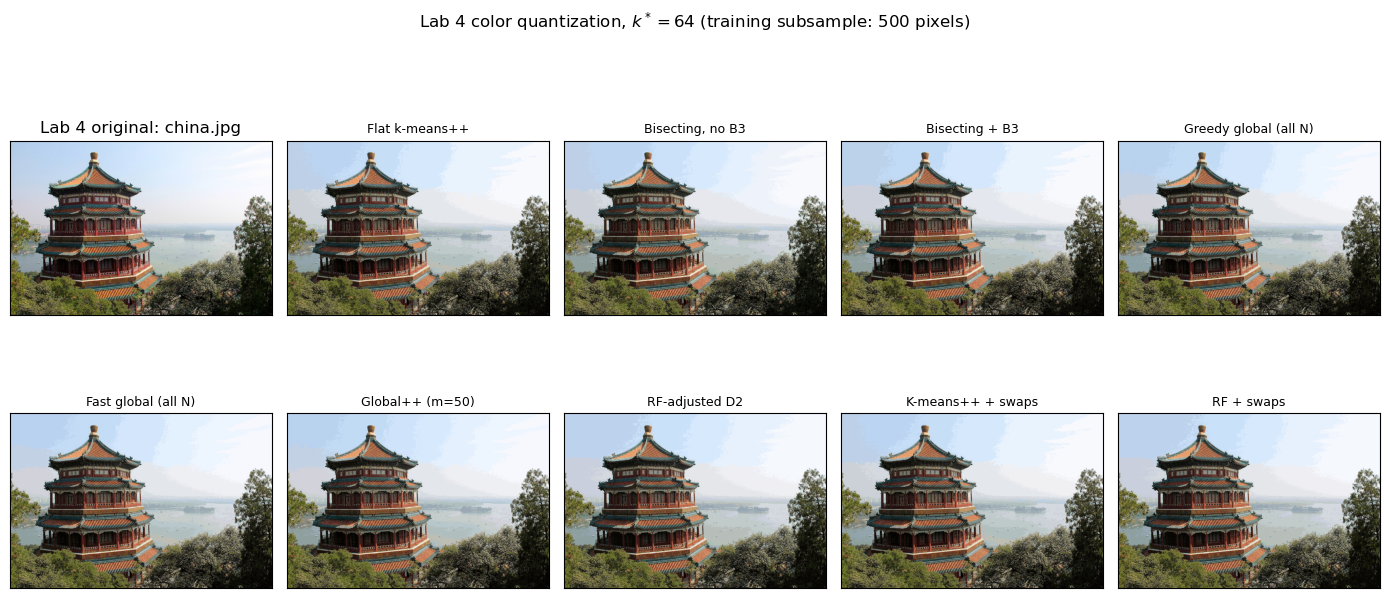

Lab 4 color example: training SSE on the same seeded 500-pixel sample:
Flat k-means++           SSE=0.6333
Bisecting, no B3         SSE=0.7015
Bisecting + B3           SSE=0.5960
Greedy global (all N)    SSE=0.5557
Fast global (all N)      SSE=0.5624
Global++ (m=50)          SSE=0.5586
RF-adjusted D2           SSE=0.6594
K-means++ + swaps        SSE=0.6185
RF + swaps               SSE=0.6438



K-means results (25 clusters, 1,250 observations):
sigma  method                              SSE      ARI
  0.1  Flat k-means++                   69.846    0.902
  0.1  Bisecting, no B3                 50.275    0.939
  0.1  Bisecting + B3                   23.785    1.000
  0.1  Greedy global (all N)            23.785    1.000
  0.1  Fast global                      23.785    1.000
  0.1  Global++                         23.785    1.000
  0.1  RF-adjusted D2                   47.939    0.948
  0.1  K-means++ + swaps                47.466    0.948
  0.1  RF + swaps                       23.785    1.000
  0.5  Flat k-means++                  267.239    0.270
  0.5  Bisecting, no B3                328.353    0.280
  0.5  Bisecting + B3                  270.085    0.286
  0.5  Greedy global (all N)           263.189    0.275
  0.5  Fast global                     263.848    0.279
  0.5  Global++                        262.249    0.286
  0.5  RF-adjusted D2                  268.742    0.

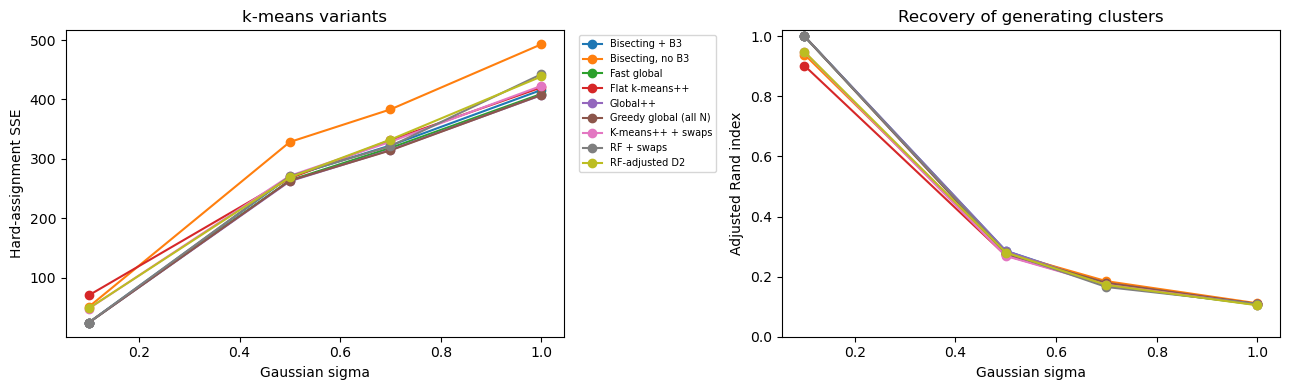

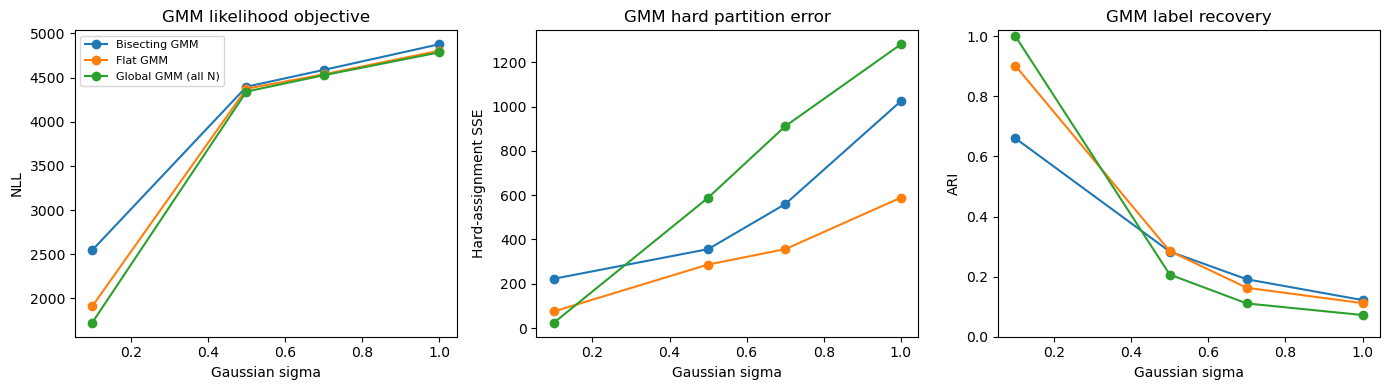

In [10]:
# (e) Lab 4, section 5.3: Summer Palace image color quantization.
from sklearn.datasets import load_sample_image
from sklearn.utils import shuffle

n_colors = 64
china = np.asarray(load_sample_image("china.jpg"), dtype=np.float64) / 255.0
w, h, channels = china.shape
assert channels == 3
image_array = china.reshape(-1, 3)
image_array_sample = shuffle(image_array, random_state=0)[:500]
k_color = n_colors
P_color = rf_leaf_proximity(image_array_sample, k_pseudo=k_color, n_trees=50, seed=11)

color_models = {}
color_models["Flat k-means++"] = fit_kmeans(image_array_sample, k_color, seed=11, n_restarts=4)
color_models["Bisecting, no B3"] = bisecting_kmeans(image_array_sample, k_color, False, seed=11)
color_models["Bisecting + B3"] = bisecting_kmeans(image_array_sample, k_color, True, seed=11)
color_models["Greedy global (all N)"] = greedy_global_kmeans(image_array_sample, k_color, max_iter=15)
color_models["Fast global (all N)"] = fast_global_kmeans(image_array_sample, k_color, max_iter=15)
color_models["Global++ (m=50)"] = globalpp_kmeans(image_array_sample, k_color, 50, seed=11)
color_models["RF-adjusted D2"] = fit_kmeans(image_array_sample, k_color, seed=11, proximity=P_color)
color_models["K-means++ + swaps"] = fit_kmeans(
    image_array_sample, k_color, seed=11, swap_rounds=1, swap_candidates=10
)
color_models["RF + swaps"] = fit_kmeans(
    image_array_sample, k_color, seed=11, proximity=P_color,
    swap_rounds=1, swap_candidates=10
)

fig, axes = plt.subplots(2, 5, figsize=(14, 7))
axes = axes.ravel()
axes[0].imshow(china)
axes[0].set_title("Lab 4 original: china.jpg")
color_results = []
for ax, (name, model) in zip(axes[1:], color_models.items()):
    centers, labels, sse = model
    full_labels = np.argmin(sqdist_to_centers(image_array, centers), axis=1)
    quantized = centers[full_labels].reshape(w, h, channels)
    ax.imshow(quantized)
    ax.set_title(name, fontsize=9)
    color_results.append((name, sse))
for ax in axes:
    ax.set_xticks([])
    ax.set_yticks([])
fig.suptitle("Lab 4 color quantization, $k^*=64$ (training subsample: 500 pixels)")
fig.tight_layout()
plt.show()
print("Lab 4 color example: training SSE on the same seeded 500-pixel sample:")
for name, sse in color_results:
    print(f"{name:24s} SSE={sse:.4f}")

# (h) The assignment's exact 5 x 5 means and 50 observations per cluster.
# Global searches check every point; global++ uses m=125 candidates.
GLOBALPP_M = 125      # floor(0.1 * 1,250), as suggested in the assignment
GRID_MAX_ITER = 15
GMM_MAX_ITER = 8

def assigned_sse(X, labels):
    total = 0.0
    for j in np.unique(labels):
        members = X[labels == j]
        if len(members): total += float(np.sum((members - members.mean(axis=0))**2))
    return total

kmeans_grid_rows = []
gmm_grid_rows = []
for sigma_idx, sigma in enumerate([0.1, 0.5, 0.7, 1.0]):
    X_grid, y_grid = make_grid_data(sigma, seed=100 + sigma_idx)
    P_grid = rf_leaf_proximity(X_grid, k_pseudo=25, n_trees=35, seed=200 + sigma_idx)
    k_target = 25
    kmeans_results = {}
    kmeans_results["Flat k-means++"] = fit_kmeans(X_grid, k_target, seed=10+sigma_idx,
                                                    n_restarts=2, max_iter=GRID_MAX_ITER)
    kmeans_results["Bisecting, no B3"] = bisecting_kmeans(X_grid, k_target, False, seed=10+sigma_idx)
    kmeans_results["Bisecting + B3"] = bisecting_kmeans(X_grid, k_target, True, seed=10+sigma_idx)
    kmeans_results["Greedy global (all N)"] = greedy_global_kmeans(
        X_grid, k_target, max_iter=GRID_MAX_ITER)
    kmeans_results["Fast global"] = fast_global_kmeans(
        X_grid, k_target, max_iter=GRID_MAX_ITER)
    kmeans_results["Global++"] = globalpp_kmeans(
        X_grid, k_target, GLOBALPP_M, seed=10+sigma_idx, max_iter=GRID_MAX_ITER)
    kmeans_results["RF-adjusted D2"] = fit_kmeans(
        X_grid, k_target, seed=10+sigma_idx, proximity=P_grid, max_iter=GRID_MAX_ITER)
    kmeans_results["K-means++ + swaps"] = fit_kmeans(
        X_grid, k_target, seed=10+sigma_idx, swap_rounds=1, swap_candidates=12, max_iter=GRID_MAX_ITER)
    kmeans_results["RF + swaps"] = fit_kmeans(
        X_grid, k_target, seed=10+sigma_idx, proximity=P_grid, swap_rounds=1,
        swap_candidates=12, max_iter=GRID_MAX_ITER)
    for name, (_, labels_k, _) in kmeans_results.items():
        kmeans_grid_rows.append({"sigma": sigma, "method": name,
                                 "SSE": assigned_sse(X_grid, labels_k),
                                 "ARI": adjusted_rand_score(y_grid, labels_k)})

    # GMM baseline and both requested incremental GMM variants.
    flat_state = flat_gmm(X_grid, k_target, seed=300+sigma_idx, max_iter=35)
    bisect_state = bisecting_gmm(X_grid, k_target, seed=300+sigma_idx, max_iter=GMM_MAX_ITER)
    global_state = global_gmm(X_grid, k_target, max_iter=GMM_MAX_ITER)
    for name, state in [("Flat GMM", flat_state), ("Bisecting GMM", bisect_state),
                        ("Global GMM (all N)", global_state)]:
        labels_g = state[3]
        gmm_grid_rows.append({"sigma": sigma, "method": name, "NLL": state[4],
                              "SSE": assigned_sse(X_grid, labels_g),
                              "ARI": adjusted_rand_score(y_grid, labels_g)})

print("\nK-means results (25 clusters, 1,250 observations):")
print(f"{'sigma':>5s}  {'method':26s} {'SSE':>12s} {'ARI':>8s}")
for row in kmeans_grid_rows:
    print(f"{row['sigma']:5.1f}  {row['method']:26s} {row['SSE']:12.3f} {row['ARI']:8.3f}")
print("\nGMM results (NLL is negative log-likelihood; lower is better):")
print(f"{'sigma':>5s}  {'method':26s} {'NLL':>12s} {'SSE':>12s} {'ARI':>8s}")
for row in gmm_grid_rows:
    print(f"{row['sigma']:5.1f}  {row['method']:26s} {row['NLL']:12.3f} {row['SSE']:12.3f} {row['ARI']:8.3f}")

# Plot clustering error and ARI trends across noise levels.
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for name in sorted(set(row['method'] for row in kmeans_grid_rows)):
    subset = [r for r in kmeans_grid_rows if r['method'] == name]
    axes[0].plot([r['sigma'] for r in subset], [r['SSE'] for r in subset], marker='o', label=name)
    axes[1].plot([r['sigma'] for r in subset], [r['ARI'] for r in subset], marker='o', label=name)
axes[0].set(xlabel='Gaussian sigma', ylabel='Hard-assignment SSE', title='k-means variants')
axes[1].set(xlabel='Gaussian sigma', ylabel='Adjusted Rand index', title='Recovery of generating clusters')
axes[0].legend(fontsize=7, bbox_to_anchor=(1.02, 1), loc='upper left')
axes[1].set_ylim(0, 1.02)
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for name in sorted(set(row['method'] for row in gmm_grid_rows)):
    subset = [r for r in gmm_grid_rows if r['method'] == name]
    axes[0].plot([r['sigma'] for r in subset], [r['NLL'] for r in subset], marker='o', label=name)
    axes[1].plot([r['sigma'] for r in subset], [r['SSE'] for r in subset], marker='o', label=name)
    axes[2].plot([r['sigma'] for r in subset], [r['ARI'] for r in subset], marker='o', label=name)
axes[0].set(xlabel='Gaussian sigma', ylabel='NLL', title='GMM likelihood objective')
axes[1].set(xlabel='Gaussian sigma', ylabel='Hard-assignment SSE', title='GMM hard partition error')
axes[2].set(xlabel='Gaussian sigma', ylabel='ARI', title='GMM label recovery')
axes[2].set_ylim(0,1.02)
axes[0].legend(fontsize=8)
fig.tight_layout()
plt.show()


### h) Results and observations

As $\sigma$ grows, neighboring groups overlap more and ARI becomes harder to maintain. SSE also rises as the data spread out. B3 can improve a split by refitting all centers, but then the partitions are no longer nested.

For GMM, NLL is the training objective; SSE and ARI describe the resulting hard labels. EM can reach different local optima, and the iteration limit may affect the results. Candidate fitting is batched to keep the experiment manageable, but the global GMM still checks every point at each step. The color experiment uses all nine k-means variants on the same 500-pixel sample; its SSE is measured on RGB values scaled to $[0,1]$.

The incremental methods follow the assignment references: [global k-means](https://hal.inria.fr/inria-00321515/document), [global++](https://arxiv.org/pdf/2211.12271), and [local-search swaps](https://proceedings.mlr.press/v97/lattanzi19a/lattanzi19a.pdf).

## Use of LLMs

ChatGPT (OpenAI) was used to clarify the assignment questions, help find and fix code errors, run the notebook and generate plots, and proofread the explanations. Its suggestions were used to correct code and wording where needed.